# Imports

In [ ]:
import numpy as np
from qiskit_aer import AerSimulator
from matplotlib import pyplot as plt
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
#TODO: Time it

# Constants

In [2]:
P_ARRAY = np.arange(0,0.11,0.01)
N_ARRAY = np.arange(2,16,1)
X_TICKS = np.arange(0,11)
Y_TICKS = np.arange(0,14)
ITERS = 100
print(P_ARRAY)
print(N_ARRAY)

[0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1 ]
[ 2  3  4  5  6  7  8  9 10 11 12 13 14 15]


# Functions

In [3]:
def getSimonsCircuit(n:int) -> QuantumCircuit:
    '''
    Get the circuit for the n-qubit Simon's algorithm with the 1s secret string.
    Args:
        n (int): The number of qubits in the input register.
    Returns:
        QuantumCircuit: The Simon's algorithm circuit.
    '''
    
    # Create the circuit for this run on Simon's algorithm.
    qreg = QuantumRegister(2*n)
    creg = ClassicalRegister(n)
    circuit = QuantumCircuit(qreg, creg)
    for m in range(n):
        circuit.h(m)
    for m in range(n):
        circuit.cx(m, n+m)
    for m in range(n):
        circuit.cx(0, n+m)
        # break   # Uncomment for "simple" oracle.
    for m in range(n):
        circuit.h(m)
    for i in range(n):
        circuit.measure(i, i)
    return circuit

In [4]:
def executeNoisyCircuit(n:int, shots:int, p1q:float, p2q:float) -> list:
    '''
    Execute a noisy version of the Simon's circuit with depolarizing noise.
    Args:
        n (int): The number of qubits.
        shots (int): The number of shots.
        p1q (float): The probability of depolarizing error for one-qubit gates.
        p2q (float): The probability of depolarizing error for two-qubit gates.
    Returns:
        list: A list of noisy samples.
    '''
    
    circ = getSimonsCircuit(n)
    noiseModel = NoiseModel()
    depolarizing1q = depolarizing_error(p1q, 1)
    depolarizing2q = depolarizing_error(p2q, 2)
    noiseModel.add_all_qubit_quantum_error(
        depolarizing1q,
        ['id', 'rz', 'sx', 'x']
    )
    noiseModel.add_all_qubit_quantum_error(
        depolarizing2q,
        ['cx']
    )
    noisySim = AerSimulator(noise_model=noiseModel)
    passManager = generate_preset_pass_manager(
        optimization_level=3, backend=noisySim
    )
    noisyCirc = passManager.run(circ)
    result = noisySim.run(noisyCirc, shots=shots).result()
    counts = result.get_counts()
    noisySamples = []
    for key, value in counts.items():
        for i in range(value):
            noisySamples.append(np.array(list(map(int, key))))
    return noisySamples

executeNoisyCircuit(2, 20, 0.1, 0.1)

[array([0, 1]),
 array([0, 1]),
 array([1, 0]),
 array([1, 1]),
 array([1, 1]),
 array([1, 1]),
 array([1, 1]),
 array([1, 1]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0])]

In [5]:
def getAllBitstrings(n:int, includeZero:bool=True) -> list:
    '''
    Returns a list of all bitstrings of length n.
    Args:
        n (int): the length of the bitstrings.
        includeZero (bool): whether to include all-zeros string (default: True).
    Returns:
        A list of all bitstrings of length n.
    '''

    bitstrings = []
    start = 0 if includeZero else 1
    for x in range(start, 2**n):
        bitstrings.append(np.array(list(map(int, list(f'{x:0{n}b}')))))
    return bitstrings

getAllBitstrings(3)

[array([0, 0, 0]),
 array([0, 0, 1]),
 array([0, 1, 0]),
 array([0, 1, 1]),
 array([1, 0, 0]),
 array([1, 0, 1]),
 array([1, 1, 0]),
 array([1, 1, 1])]

In [6]:
def solveSubsystem(subsystem:np.array) -> np.array:
    '''
    Solves the given subsystem of equations.
    Args:
        subsystem (np.array): the subsystem of equations to solve.
    Returns:
        A bitstring that satisfies the subsystem of equations,
        or the all-zeros string if no such bitstring exists.
    '''

    n = len(subsystem[0])
    zeros = np.zeros(n-1, int)
    bitstrings = getAllBitstrings(n, False)
    for bits in bitstrings:
        if np.allclose((subsystem @ bits) % 2, zeros):
            return bits
    return np.zeros(n, int)

print(solveSubsystem(np.array([np.array([1, 0, 1]), np.array([1, 1, 0])])))
print(solveSubsystem(np.array([np.array([0, 1, 1]), np.array([0, 1, 0])])))

[1 1 1]
[1 0 0]


In [7]:
def validateSubsystem(subsystem:np.array, secretString:np.array) -> np.array:
    '''
    Validate that the provided secret string solves the given subsystem.
    Args:
        subsystem (np.array): the subsystem of equations to solve.
        secretString (np.array): the secret string.
    Returns:
        The secret string if it satisfies the subsystem of equations,
        or the all-zeros string if no such bitstring exists.
    '''

    n = len(subsystem[0])
    zeros = np.zeros(n-1, int)
    if np.allclose((subsystem @ secretString) % 2, zeros):
        return secretString
    return np.zeros(n, int)

print(solveSubsystem(np.array([np.array([1, 0, 1]), np.array([1, 1, 0])])))
print(solveSubsystem(np.array([np.array([0, 1, 1]), np.array([0, 1, 0])])))

[1 1 1]
[1 0 0]


In [8]:
def solveNoisySystem(
        noisySamples:np.array,
        secretString:np.array,
        trials:int=50,
        solveSystem:bool=True
    ) -> bool:
    '''
    Solves the given noisy system of equations.
    Args:
        noisySamples (np.array): the noisy samples of equations.
        secretString (np.array): the secret string.
        trials (int): the number of random subsystems to try (default: 50).
        solveSystem (bool): Whether to solve or validate the system.
            Validating uses knowledge of s for computational efficiency.
    Returns:
        True if the secret string can be recovered, False otherwise.
    '''

    n = len(secretString)
    for i in range(trials):
        indices = np.random.choice(len(noisySamples), n-1, replace=False)
        subsystem = np.array([noisySamples[i] for i in indices])
        if solveSystem:
            solution = solveSubsystem(subsystem)
        else:
            solution = validateSubsystem(subsystem, secretString)
        if np.allclose(solution, secretString):
            return True
    return False

solveNoisySystem(
    [
        np.array([0, 0, 1]),
        np.array([1, 0, 1]),
        np.array([1, 1, 0]),
        np.array([0, 0, 0]),
        np.array([1, 1, 0]),
        np.array([0, 0, 0]),
        np.array([0, 1, 1]),
        np.array([0, 1, 1]),
        np.array([0, 0, 0]),
        np.array([0, 0, 0]),
        np.array([1, 0, 0]),
        np.array([0, 0, 0]),
        np.array([0, 0, 1]),
        np.array([0, 1, 1]),
        np.array([0, 1, 1]),
        np.array([1, 1, 0]),
        np.array([1, 0, 1]),
        np.array([0, 1, 0]),
        np.array([0, 1, 0]),
        np.array([1, 1, 0]),
        np.array([1, 0, 0]),
        np.array([0, 1, 0]),
        np.array([1, 0, 1])
    ], [1, 1, 1]
)

True

In [9]:
def runExperiment(expType:str) -> np.array:
    '''
    Run the experiment for the given type of depolarizing noise.
    Plot and return the success heatmap.
    Args:
        expType (str): The type of depolarizing noise to test.
        Should be one of 'One- & Two-qubit', 'One-qubit', or 'Two-qubit'.
    Returns:
        np.array: A heatmap of the success probabilities for all n and p.
    '''

    try:
        successHeatmap = np.load(f'data/successHeatmap{expType}.npy')
        with open(f'data/iterations{expType}.txt', 'r') as file:
            start = int(file.read()) + 1
    except:
        successHeatmap = np.zeros((len(N_ARRAY), len(P_ARRAY)))
        start = 1
    for iter in range(start, ITERS + 1):
        print(f'Iteration {iter}')
        for i, n in enumerate(N_ARRAY):
            print(f'n = {n}:\t', end=' ')
            for j, p in enumerate(P_ARRAY):
                print(f'p = {np.round(p, 2)}', end=' ')
                shots = n + 20  # n + 20 chosen to make P(failure|p=0) < 1/1,000,000
                secretString = np.array([1] * n)
                if expType == 'One- & Two-qubit':
                    noisySamples = executeNoisyCircuit(n, shots, p, p)
                elif expType == 'One-qubit':
                    noisySamples = executeNoisyCircuit(n, shots, p, 0)
                elif expType == 'Two-qubit':
                    noisySamples = executeNoisyCircuit(n, shots, 0, p)
                successHeatmap[i,j] += solveNoisySystem(
                    np.array(noisySamples), secretString, solveSystem=False
                )
            print('\n', end='')
            np.save(f'data/successHeatmap{expType}.npy', successHeatmap)
            with open(f'data/iterations{expType}.txt', 'w+') as file:
                file.write(str(iter))

    fig = plt.figure(figsize=(10,6))
    with open(f'data/iterations{expType}.txt', 'r') as file:
        numTrials = int(file.read())
    successHeatmap = np.load(f'data/successHeatmap{expType}.npy')
    successHeatmap /= numTrials
    plt.imshow(successHeatmap[::-1])
    plt.xlabel(fr'$p$ (Strength of {expType} Depolarizing Channel)')
    plt.ylabel(r'$n$ (Size of System)')
    plt.xticks(X_TICKS, P_ARRAY)
    plt.yticks(Y_TICKS, N_ARRAY[::-1])
    plt.colorbar()
    plt.title(fr'Probability of Recovering $s$ out of {int(numTrials)} Trials')
    plt.show()

    return successHeatmap

# Experiment 1: Single-qubit Depolarizing Channel

Iteration 1
n = 2:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 3:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 4:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 5:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 6:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 7:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 8:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 9:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 10:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 11:	 p = 0.0 p = 0.01 p = 0.0

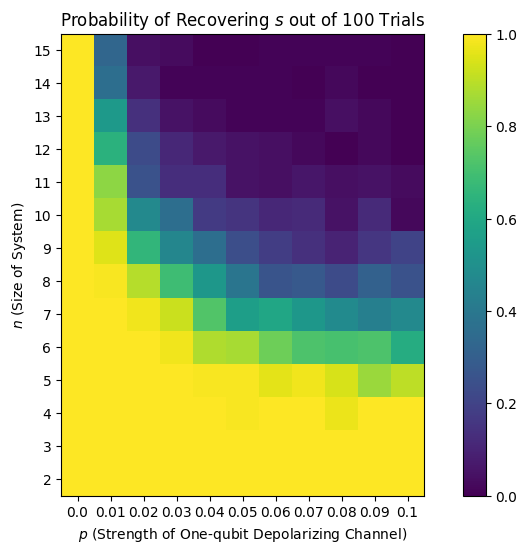

array([[1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  ],
       [1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  ],
       [1.  , 1.  , 1.  , 1.  , 1.  , 0.99, 1.  , 1.  , 0.97, 1.  , 1.  ],
       [1.  , 1.  , 1.  , 1.  , 0.99, 0.99, 0.96, 0.98, 0.94, 0.85, 0.9 ],
       [1.  , 1.  , 1.  , 0.98, 0.88, 0.87, 0.78, 0.72, 0.71, 0.72, 0.62],
       [1.  , 1.  , 0.98, 0.92, 0.73, 0.56, 0.59, 0.53, 0.48, 0.43, 0.47],
       [1.  , 0.99, 0.89, 0.69, 0.53, 0.39, 0.26, 0.28, 0.23, 0.31, 0.25],
       [1.  , 0.95, 0.66, 0.46, 0.36, 0.24, 0.18, 0.14, 0.1 , 0.16, 0.2 ],
       [1.  , 0.87, 0.47, 0.36, 0.17, 0.15, 0.11, 0.12, 0.05, 0.12, 0.02],
       [1.  , 0.83, 0.25, 0.13, 0.13, 0.05, 0.04, 0.06, 0.04, 0.05, 0.03],
       [1.  , 0.64, 0.23, 0.11, 0.07, 0.05, 0.04, 0.02, 0.  , 0.02, 0.  ],
       [1.  , 0.54, 0.14, 0.05, 0.03, 0.01, 0.01, 0.01, 0.04, 0.02, 0.  ],
       [1.  , 0.36, 0.07, 0.01, 0.01, 0.01, 0.01, 0.  , 0.02, 0.  , 0.  ],
       [1.  , 0.33, 0.04,

In [10]:
runExperiment('One-qubit')

Iteration 1
n = 2:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 3:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 4:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 5:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 6:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 7:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 8:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 9:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 10:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 11:	 p = 0.0 p = 0.01 p = 0.0

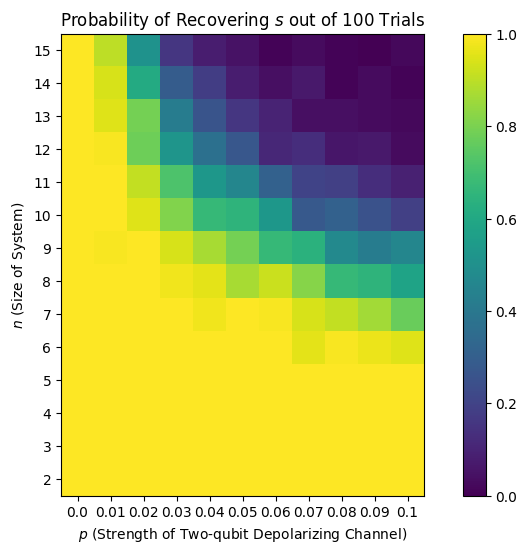

array([[1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  ],
       [1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  ],
       [1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  ],
       [1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  ],
       [1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 0.96, 0.99, 0.97, 0.95],
       [1.  , 1.  , 1.  , 1.  , 0.98, 1.  , 0.99, 0.94, 0.91, 0.86, 0.77],
       [1.  , 1.  , 1.  , 0.98, 0.96, 0.87, 0.92, 0.82, 0.67, 0.65, 0.58],
       [1.  , 0.99, 1.  , 0.94, 0.87, 0.79, 0.67, 0.64, 0.47, 0.42, 0.46],
       [1.  , 1.  , 0.95, 0.81, 0.67, 0.65, 0.53, 0.28, 0.31, 0.25, 0.19],
       [1.  , 1.  , 0.91, 0.72, 0.53, 0.46, 0.31, 0.2 , 0.19, 0.13, 0.09],
       [1.  , 0.99, 0.78, 0.52, 0.37, 0.27, 0.11, 0.13, 0.06, 0.07, 0.03],
       [1.  , 0.95, 0.79, 0.42, 0.26, 0.16, 0.1 , 0.04, 0.04, 0.03, 0.02],
       [1.  , 0.94, 0.61, 0.29, 0.18, 0.08, 0.04, 0.07, 0.01, 0.03, 0.01],
       [1.  , 0.9 , 0.51,

In [11]:
runExperiment('Two-qubit')

Iteration 1
n = 2:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 3:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 4:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 5:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 6:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 7:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 8:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 9:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 10:	 p = 0.0 p = 0.01 p = 0.02 p = 0.03 p = 0.04 p = 0.05 p = 0.06 p = 0.07 p = 0.08 p = 0.09 p = 0.1 
n = 11:	 p = 0.0 p = 0.01 p = 0.0

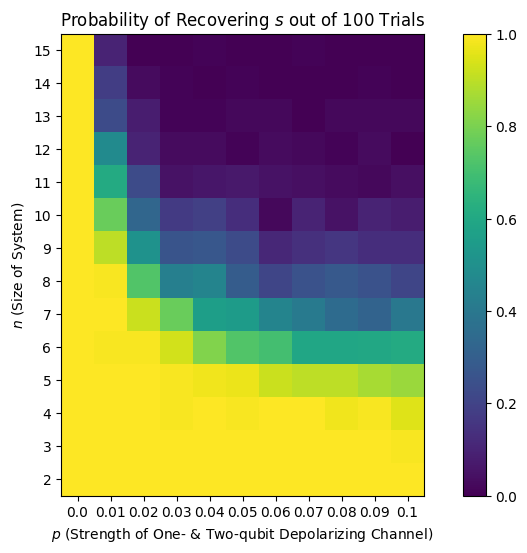

array([[1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  ],
       [1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 0.99],
       [1.  , 1.  , 1.  , 0.99, 1.  , 0.99, 1.  , 1.  , 0.98, 0.99, 0.95],
       [1.  , 1.  , 1.  , 0.99, 0.98, 0.97, 0.92, 0.9 , 0.9 , 0.87, 0.85],
       [1.  , 0.99, 0.99, 0.93, 0.81, 0.73, 0.7 , 0.59, 0.59, 0.6 , 0.61],
       [1.  , 1.  , 0.92, 0.77, 0.56, 0.55, 0.45, 0.41, 0.35, 0.32, 0.4 ],
       [1.  , 0.99, 0.73, 0.43, 0.45, 0.29, 0.21, 0.25, 0.28, 0.25, 0.21],
       [1.  , 0.9 , 0.51, 0.26, 0.27, 0.23, 0.11, 0.14, 0.16, 0.13, 0.13],
       [1.  , 0.77, 0.33, 0.17, 0.19, 0.13, 0.02, 0.1 , 0.05, 0.1 , 0.08],
       [1.  , 0.61, 0.23, 0.05, 0.06, 0.07, 0.05, 0.04, 0.03, 0.02, 0.04],
       [1.  , 0.48, 0.1 , 0.03, 0.03, 0.01, 0.03, 0.02, 0.01, 0.03, 0.  ],
       [1.  , 0.23, 0.08, 0.01, 0.01, 0.02, 0.02, 0.  , 0.02, 0.02, 0.02],
       [1.  , 0.18, 0.03, 0.01, 0.  , 0.01, 0.  , 0.  , 0.  , 0.01, 0.  ],
       [1.  , 0.1 , 0.  ,

In [12]:
runExperiment('One- & Two-qubit')